# 01 Fehlende Stundenwerte füllen

Teil 1: Daten

**Worum es geht**
- Auswertungen auf Stundenebene, etwa das GNN in den weiteren Versuchen, brauchen je Station für jede Stunde einen Wert. Im Carpet-Plot aus Notebook 12 (Bild Tag gegen Uhrzeit) sind bei vielen Stationen ganze Zeiträume leer
- Wie viel fehlt, und welche Art von Lücke ist es?
- Lassen sich die Lücken so füllen, dass Energie und Volumen zum Zählerstand passen?
- Wie gut trifft das Verfahren an künstlich gelöschten Stunden?

**Daten**
- liest: Stundenreihen aus Notebook 00 über `src/nb00_daten.py`, Tagesmittel der Außentemperatur (DWD Kitzingen)
- schreibt: `data/processed/real_meters_gefuellt/` (gitignored), Spalten wie Notebook 00 plus `quelle` und `luecke_h`
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/luecken.py`, Tests in `tests/test_luecken.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import luecken as lu
from src import nb00_daten as nb00
from src import stationsbilder as sb

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)

## 1 Wie viel fehlt und welcher Art

- Messspanne je Zähler: erster bis letzter Zeitpunkt mit einem Messwert
- Eine Stunde gilt als gemessen, wenn mindestens ein Momentanwert da ist (Volumenstrom, Leistung, Spreizung, Vorlauf, Rücklauf)
- Die Lücken werden nach Länge eingeteilt, weil verschiedene Ursachen dahinterstecken

In [2]:
serien = nb00.lade_serien(leere_stunden_entfernen=False, zaehlerstaende_ergaenzen=False)
von = min(s.index.min() for s in serien.values()).normalize()
bis = max(s.index.max() for s in serien.values()).normalize() + pd.Timedelta(days=1)
t_tag = lu.tagesmittel_aussen(von, bis, allow_download=False)

KLASSEN = [(1, 3, "bis 3 h"), (4, 24, "4 bis 24 h"), (25, 7 * 24, "1 bis 7 Tage"),
           (7 * 24 + 1, 10**9, "über 7 Tage")]
zeilen = []
for zid, df in serien.items():
    if not df[lu.MOMENT].notna().any().any():
        continue
    d = lu.auf_raster(df)
    gem = d[lu.MOMENT].notna().any(axis=1).to_numpy()
    a, b = lu._laeufe(~gem)
    for i, j in zip(a, b):
        L = j - i + 1
        klasse = next(n for lo, hi, n in KLASSEN if lo <= L <= hi)
        zeilen.append({"zaehler": zid, "laenge_h": L, "klasse": klasse,
                       "am_anfang": i == 0, "start": d.index[i]})
    zeilen.append({"zaehler": zid, "laenge_h": 0, "klasse": "gemessen", "am_anfang": False,
                   "start": d.index[0], "gemessen_h": int(gem.sum()), "raster_h": len(d)})
lk = pd.DataFrame(zeilen)
raster_h = int(lk["raster_h"].sum())
gemessen_h = int(lk["gemessen_h"].sum())
luecken = lk[lk["klasse"] != "gemessen"]
print(f"{lk['zaehler'].nunique()} Zähler, {raster_h:,} Rasterstunden in den Messspannen, "
      f"davon {raster_h - gemessen_h:,} ohne Messung ({(raster_h - gemessen_h) / raster_h:.1%})")
tab = luecken.groupby("klasse").agg(luecken=("laenge_h", "size"), stunden=("laenge_h", "sum"),
                                    zaehler=("zaehler", "nunique"))
tab = tab.reindex([n for _, _, n in KLASSEN])
tab["anteil_fehlend"] = (tab["stunden"] / tab["stunden"].sum()).round(3)
tab

93 Zähler, 2,128,400 Rasterstunden in den Messspannen, davon 434,269 ohne Messung (20.4%)


,luecken,stunden,zaehler,anteil_fehlend
klasse,,,,
bis 3 h,972,995,93,0.002
4 bis 24 h,15910,365404,49,0.841
1 bis 7 Tage,10,697,4,0.002
über 7 Tage,16,67173,11,0.155


In [3]:
tp = luecken[luecken["laenge_h"] == 23]
print(f"Lücken mit genau 23 h: {len(tp):,} ({tp['laenge_h'].sum():,} Stunden, {tp['zaehler'].nunique()} Zähler)")
print("Startstunde dieser Lücken:", tp["start"].dt.hour.value_counts().head(3).to_dict())
rand = luecken[luecken["am_anfang"]]
print(f"Lücken am Anfang der Spanne (nur Zählerstand davor): {len(rand)} Zähler, "
      f"{rand['laenge_h'].sum():,} Stunden, Median {rand['laenge_h'].median() / 24:.0f} Tage")
lang = luecken[luecken["laenge_h"] > 7 * 24].sort_values("laenge_h", ascending=False)
lang.assign(tage=(lang["laenge_h"] / 24).round(0))[["zaehler", "start", "tage", "am_anfang"]].head(10)

Lücken mit genau 23 h: 15,862 (364,826 Stunden, 45 Zähler)
Startstunde dieser Lücken: {0: 15862}
Lücken am Anfang der Spanne (nur Zählerstand davor): 0 Zähler, 0 Stunden, Median nan Tage


,zaehler,start,tage,am_anfang
6682,68956359,2022-01-25 17:00:00,652.0,False
4845,68956348,2022-02-04 12:00:00,642.0,False
9232,68956371,2022-05-20 11:00:00,537.0,False
16632,80912156,2024-05-13 17:00:00,235.0,False
11987,72135441,2024-08-20 00:00:00,213.0,False
12390,72135443,2024-08-20 00:00:00,124.0,False
12393,72135443,2024-12-22 17:00:00,88.0,False
11573,69631918,2024-07-10 13:00:00,75.0,False
385,53198226,2023-09-07 14:00:00,62.0,False
16709,80912165,2024-06-26 21:00:00,45.0,False


- In den Messspannen der 93 Zähler fehlen 434.269 von 2.128.400 Stunden (20,4 %)
- Gut vier Fünftel (365.404 Stunden in Lücken von 4 bis 24 Stunden) stammen aus dem frühen Export mit einem Wert je Tag um 23 Uhr: 15.862 Lücken von genau 23 Stunden bei 45 Zählern
- Der Rest sind vor allem 16 Ausfälle über eine Woche bei 11 Zählern (67.173 Stunden)
- Eine Randspanne vor dem ersten Momentanwert gibt es nicht mehr: Notebook 00 verwirft Zeilen, die nur einen Zählerstand haben

## 2 Verfahren

Rechnung in `lu.fuelle_zaehler`:

- Fehlt nur ein Kanal, wird er aus den anderen berechnet (Quelle `ergaenzt`): $\Delta T = T_{VL} - T_{RL}$ und $P = k \cdot \dot V \cdot \Delta T$. Lücken bis 3 Stunden werden linear gefüllt (`interpoliert`)
- Längere Lücken: typisches Profil der Station je Tagesstunde und Klasse der Tagesmitteltemperatur (fünf Klassen, DWD Kitzingen), nur aus eigenen gemessenen Stunden. Bei plausiblen Zählerständen an beiden Rändern wird auf die Zählerdifferenz skaliert (`bilanziert`), sonst bleibt das reine Profil (`modelliert`)
- Unplausibel heißt: Zählertausch, negativer Zuwachs oder mehr als die doppelte höchste gemessene Rate. Der Vorlauf geht vom Rand über 72 Stunden ins Profil über, Rücklauf = Vorlauf minus Spreizung. Gemessene Zählerstände bleiben unverändert
- Je Station: $k$ = Median von $P / (\dot V \cdot \Delta T)$ (Nennwert 1,163e-3), $\rho$ = Summe der Momentanwerte geteilt durch die Zählerdifferenz

In [4]:
fak = []
for zid, df in serien.items():
    if not df[lu.MOMENT].notna().any().any():
        continue
    d = lu.auf_raster(df)
    rho_e, rho_v = lu.rho_faktoren(d)
    fak.append({"zaehler": zid, "k": lu.k_faktor(d), "rho_e": rho_e, "rho_v": rho_v})
fak = pd.DataFrame(fak).set_index("zaehler")
print(fak.describe().round(4).to_string())
abw = fak[(fak["rho_e"] - 1).abs() > 0.1]
print(f"\nStationen mit mehr als 10 % Abweichung zwischen Leistungssumme und Energiezähler: {len(abw)} von {len(fak)}")
abw.round(3)

             k    rho_e    rho_v
count  93.0000  93.0000  93.0000
mean    0.0012   1.0086   1.0080
std     0.0000   0.0935   0.0962
min     0.0011   0.6390   0.5864
25%     0.0011   0.9864   0.9906
50%     0.0012   1.0000   1.0036
75%     0.0012   1.0221   1.0268
max     0.0012   1.4515   1.3611

Stationen mit mehr als 10 % Abweichung zwischen Leistungssumme und Energiezähler: 11 von 93


,k,rho_e,rho_v
zaehler,,,
68956355,0.001,1.229,1.074
68956361,0.001,0.743,0.701
68956365,0.001,1.321,1.311
68956369,0.001,1.145,1.092
69527345,0.001,0.639,0.586
72135490,0.001,0.808,0.702
80912170,0.001,1.232,1.361
80912178,0.001,1.150,1.141
80912191,0.001,1.161,1.136


- $k$ ist praktisch konstant (Median 1,152e-3, 5 bis 95 % zwischen 1,146e-3 und 1,157e-3) und taugt zum Ergänzen
- $\rho$ liegt im Median bei 1,000. Bei 11 von 93 Stationen weicht es um mehr als 10 % ab (0,64 bis 1,45), die Bilanz rechnet deshalb mit $\rho \cdot \Delta E$
- Die Ursache der Abweichung ist ungeklärt

## 3 Prüfung an künstlich gelöschten Stunden

- Je Zähler ein voll gemessenes Fenster von 28 Tagen, gelöscht nach drei Mustern: `kurz` (zehn Lücken à 3 Stunden), `tagesphase` (nur 23 Uhr bleibt), `block` (ganzes Fenster)
- Vergleich: Verfahren, Profil ohne Bilanz (`nur_profil`) und lineare Interpolation (`linear`)
- Maß: mittlerer absoluter Fehler (MAE) je Kanal. 30 Zähler mit fester Startzahl gezogen, 29 davon auswertbar

In [5]:
val = lu.validiere(serien, t_tag, n_zaehler=30, seed=0)
spalten = ["mae_flow", "mae_power", "mae_vl", "mae_rt", "stundenenergie_rel", "tagesenergie_rel"]
print(f"{val['zaehler'].nunique()} Zähler, Fenster je Art:", val.groupby("art")["zaehler"].nunique().to_dict())
val.groupby(["art", "verfahren"])[spalten].median().round(3)

29 Zähler, Fenster je Art: {'block': 29, 'kurz': 29, 'tagesphase': 29}


mae_flow  mae_power  mae_vl  mae_rt  stundenenergie_rel  tagesenergie_rel
art        verfahren                                                                            
block      linear        43.685      1.703   5.895   5.985               0.572             0.231
           nur_profil    38.830      1.000   4.319   4.909               0.520             0.247
           verfahren     33.517      1.024   4.319   5.647               0.521             0.233
kurz       linear        37.150      1.232   4.013   4.452               0.410             0.169
           nur_profil    37.150      1.232   4.013   4.452               0.380             0.148
           verfahren     37.150      1.232   4.013   4.452               0.380             0.148
tagesphase linear        43.868      1.454   3.494   6.837               0.425             0.023
           nur_profil    48.960      1.345   3.654   6.396               0.410             0.017
           verfahren     39.745      1.333   3.654   6.377               0.410             0.015

In [6]:
#wie oft ist das Verfahren je Zähler besser als lineare Interpolation
breit = val.pivot_table(index=["zaehler", "art"], columns="verfahren", values=spalten)
besser = pd.DataFrame({c: (breit[(c, "verfahren")] < breit[(c, "linear")]).groupby("art").mean()
                       for c in spalten}).round(2)
besser

,mae_flow,mae_power,mae_vl,mae_rt,stundenenergie_rel,tagesenergie_rel
art,,,,,,
block,0.55,0.66,0.62,0.59,0.79,0.45
kurz,0.00,0.00,0.00,0.00,0.45,0.48
tagesphase,0.66,0.76,0.66,0.55,0.79,0.83


- Tagesphase (häufigster Fall): Verfahren besser als linear. Median über 29 Zähler: Volumenstrom 39,7 statt 43,9 l/h, relativer Fehler der Tagesenergie 0,015 statt 0,023. Vorn bei 66 % bzw. 83 % der Zähler
- Rücklauf in allen Varianten schwach, Fehler rund 6,4 K
- Block: Verfahren besser als linear (Volumenstrom 33,5 gegen 43,7 l/h, Leistung 1,02 gegen 1,70 kW). Eine Gerade über Monate kennt keinen Jahresgang
- Kurze Lücken: alle Varianten füllen hier gleich, nämlich linear

## 4 Alle Zähler füllen

- Alle Zähler füllen und schreiben
- Danach Prüfung: keine leere Zelle, Messwerte unverändert, Physik plausibel

In [7]:
gefuellt = lu.fuelle_alle(serien, t_tag=t_tag, schreiben=True)
ueb = lu.uebersicht(gefuellt)
summe = ueb.sum()
print(f"{len(gefuellt)} Zähler geschrieben nach {lu.GEFUELLT_DIR.relative_to(ROOT)}")
print(f"{int(summe.sum()):,} Stunden gesamt")
pd.DataFrame({"stunden": summe, "anteil": (summe / summe.sum()).round(4)})

93 Zähler geschrieben nach data/processed/real_meters_gefuellt
2,128,400 Stunden gesamt


,stunden,anteil
quelle,,
gemessen,1676633,0.7877
ergaenzt,17498,0.0082
interpoliert,995,0.0005
bilanziert,433251,0.2036
modelliert,23,0.0000


In [8]:
leer = sum(int(g[lu.MOMENT + lu.STAENDE].isna().sum().sum()) for g in gefuellt.values())
geaendert = 0
stand_geaendert = 0
for zid, g in gefuellt.items():
    roh = serien[zid].reindex(g.index)
    gem = g["quelle"] == "gemessen"
    geaendert += int((g.loc[gem, lu.MOMENT] - roh.loc[gem, lu.MOMENT]).abs().gt(1e-9).sum().sum())
    bek = roh["energy"].notna()
    stand_geaendert += int((g.loc[bek, "energy"] - roh.loc[bek, "energy"]).abs().gt(1e-6).sum())
alle = pd.concat(gefuellt.values())
neu = alle[alle["quelle"].isin(["bilanziert", "modelliert"])]
print(f"leere Zellen: {leer}")
print(f"veränderte Messwerte in gemessenen Stunden: {geaendert}")
print(f"veränderte gemessene Energiestände: {stand_geaendert}")
print(f"Rücklauf unter 10 °C in gefüllten Stunden: {(neu['rt'] < 10).mean():.2%}")
print(f"Spreizung negativ in gefüllten Stunden: {(neu['dt'] < 0).mean():.2%}")
alle.groupby("quelle")[["flow", "power", "dt", "vl", "rt"]].median().round(2)

leere Zellen: 0
veränderte Messwerte in gemessenen Stunden: 0
veränderte gemessene Energiestände: 0
Rücklauf unter 10 °C in gefüllten Stunden: 0.02%
Spreizung negativ in gefüllten Stunden: 0.00%


,flow,power,dt,vl,rt
quelle,,,,,
bilanziert,56.53,1.12,16.89,65.00,42.61
ergaenzt,8900.00,241.79,18.80,81.10,58.00
gemessen,52.00,0.65,14.70,69.30,45.50
interpoliert,69.00,1.06,13.05,68.65,48.20
modelliert,9241.75,252.93,23.66,81.35,57.84


In [9]:
#welche Stationen bestehen am stärksten aus gefüllten Stunden
anteil = ueb.div(ueb.sum(axis=1), axis=0)
anteil["gefuellt"] = 1 - anteil["gemessen"] - anteil["ergaenzt"]
anteil.sort_values("gefuellt", ascending=False).round(3).head(10)

quelle,gemessen,ergaenzt,interpoliert,bilanziert,modelliert,gefuellt
zaehler,,,,,,
68956359,0.456,0.00,0.000,0.544,0.000,0.544
68956348,0.456,0.00,0.000,0.544,0.000,0.544
72135441,0.466,0.00,0.002,0.533,0.000,0.534
72135443,0.467,0.00,0.001,0.532,0.000,0.533
58177384,0.511,0.00,0.000,0.488,0.000,0.489
68956371,0.577,0.00,0.000,0.423,0.000,0.423
66761022,0.607,0.00,0.003,0.390,0.000,0.393
58202380,0.000,0.61,0.000,0.389,0.001,0.390
58177363,0.610,0.00,0.000,0.390,0.000,0.390


- Keine leere Zelle, kein Messwert und kein Energiestand verändert
- Von 2.128.400 Stunden: 78,8 % gemessen, 0,8 % ergänzt (meist Spreizung), 995 interpoliert, 20,4 % bilanziert, 23 modelliert
- Plausibel: Rücklauf unter 10 °C in 0,02 % der gefüllten Stunden, negative Spreizung nie
- Höchster Füllanteil: 68956359 und 68956348 (je 54 %), 72135441 und 72135443 (je 53 %), 58177384 (49 %)

## 5 Carpet vorher und nachher

- Zähler 68956351, bis November 2022 ein Wert pro Tag
- Oben die Reihe aus Notebook 00, in der Mitte gefüllt, unten die Quelle je Stunde. Danach eine Woche im Detail

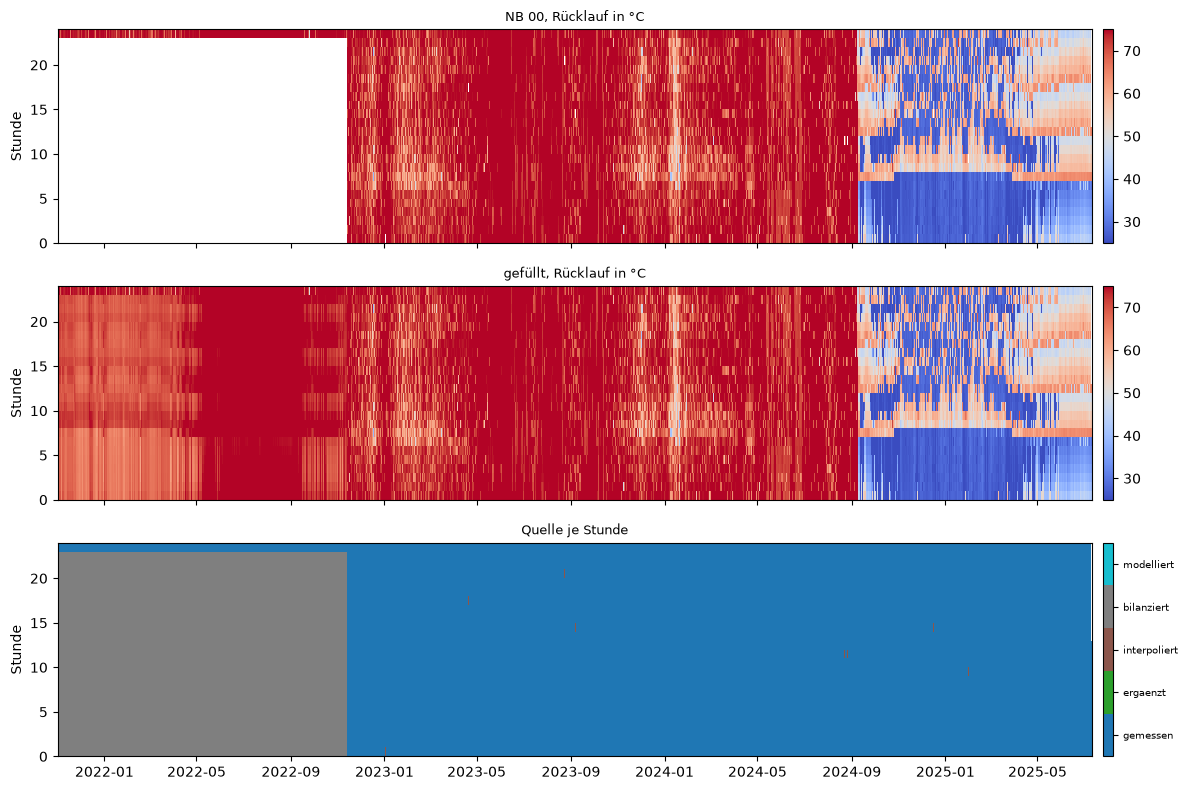

quelle
gemessen        23683
bilanziert       8648
interpoliert       11


In [10]:
ZAEHLER = 68956351
vorher = lu.auf_raster(serien[ZAEHLER])
nachher = gefuellt[ZAEHLER]
codes = {q: i for i, q in enumerate(lu.QUELLEN)}

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (df, titel) in zip(axes[:2], [(vorher, "NB 00, Rücklauf in °C"), (nachher, "gefüllt, Rücklauf in °C")]):
    m = sb.carpetmatrix(df, kanal="rt")
    x0, x1 = mdates.date2num(m.columns[0]), mdates.date2num(m.columns[-1])
    bild = ax.imshow(m.to_numpy(float), aspect="auto", origin="lower", extent=(x0, x1, 0, 24),
                     cmap="coolwarm", vmin=25, vmax=75, interpolation="nearest")
    ax.set_title(titel, fontsize=9)
    ax.set_ylabel("Stunde")
    fig.colorbar(bild, ax=ax, pad=0.01, fraction=0.025)
q = nachher.assign(q=nachher["quelle"].map(codes))
m = sb.carpetmatrix(q, kanal="q")
cmap = plt.get_cmap("tab10", len(codes))
bild = axes[2].imshow(m.to_numpy(float), aspect="auto", origin="lower", extent=(x0, x1, 0, 24),
                      cmap=cmap, vmin=-0.5, vmax=len(codes) - 0.5, interpolation="nearest")
cb = fig.colorbar(bild, ax=axes[2], pad=0.01, fraction=0.025, ticks=range(len(codes)))
cb.ax.set_yticklabels(list(codes), fontsize=7)
axes[2].set_title("Quelle je Stunde", fontsize=9)
axes[2].set_ylabel("Stunde")
axes[2].xaxis_date()
fig.tight_layout()
plt.show()
print(nachher["quelle"].value_counts().to_string())

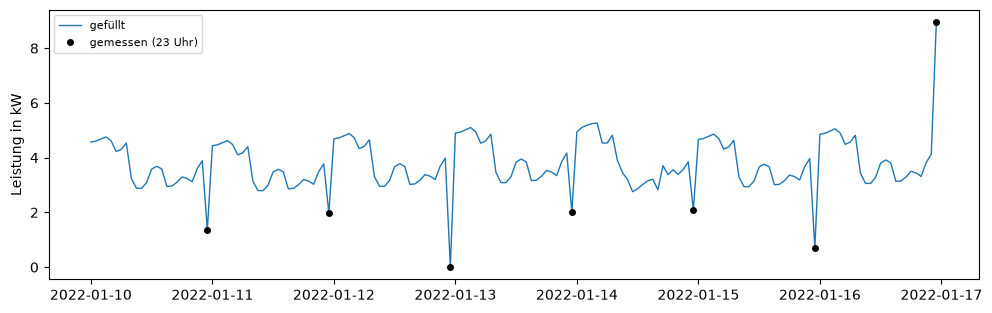

Tagesenergie aus dem gefüllten Zähler in kWh: [85.0, 89.0, 93.0, 92.0, 89.0, 96.0]


In [11]:
woche = nachher.loc["2022-01-10":"2022-01-16"]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(woche.index, woche["power"], lw=1, label="gefüllt")
pkt = woche[woche["quelle"].isin(["gemessen", "ergaenzt"])]
ax.plot(pkt.index, pkt["power"], "o", color="black", ms=4, label="gemessen (23 Uhr)")
ax.set_ylabel("Leistung in kW")
ax.legend(fontsize=8)
plt.show()
tag = woche["energy"].resample("D").last().diff().dropna()
print("Tagesenergie aus dem gefüllten Zähler in kWh:", tag.round(1).to_list())

- Carpet geschlossen, bis November 2022 fast alles bilanziert
- Der gefüllte Rücklauf liegt unter den 23-Uhr-Werten: die Zählerstände verlangen etwa 4 K Spreizung, um 23 Uhr waren es nur 0,7 K. Passt zum Winter 2022/23 (23 Uhr 1,05 K gegen Tagesmittel 2,25 K)
- Die Tagesenergie stimmt per Konstruktion (10. bis 16.01.2022: 85 bis 96 kWh je Tag), der Tagesgang stammt aus dem Profil

## 6 Gefüllte Dateien lesen

- Für das Graphennetzwerk: Einlesen mit `lu.lade_gefuellt()`, Spalten wie Notebook 00
- `quelle` = Herkunft der Stunde, `luecke_h` = Länge der zugehörigen Lücke (0 bei gemessenen Stunden)
- Halbwegs gesicherte Stunden: `quelle != "modelliert"` und `luecke_h <= 24`

In [12]:
probe = lu.lade_gefuellt(zaehler=[ZAEHLER])[ZAEHLER]
print(probe.columns.to_list())
streng = probe[(probe["quelle"] != "modelliert") & (probe["luecke_h"] <= 24)]
print(f"{len(probe):,} Stunden, davon {len(streng):,} mit Quelle gemessen/ergänzt/interpoliert "
      f"oder bilanziert in Lücken bis 24 h")
probe.head(3)

['flow', 'power', 'dt', 'vl', 'rt', 'energy', 'volume', 'quelle', 'luecke_h']
32,342 Stunden, davon 32,342 mit Quelle gemessen/ergänzt/interpoliert oder bilanziert in Lücken bis 24 h


,flow,power,dt,vl,rt,energy,volume,quelle,luecke_h
Timestamp,,,,,,,,,
2021-11-01 23:00:00,888.0000,0.0790,0.0000,75.6000,75.5000,17477.0000,5865.5450,gemessen,0
2021-11-02 00:00:00,899.0692,2.9001,2.8067,72.9849,70.1782,17478.4972,5866.4397,bilanziert,23
2021-11-02 01:00:00,896.0645,2.8010,2.7200,72.0381,69.3182,17481.3623,5867.3384,bilanziert,23


- Beispiel 68956351: alle 32.342 Stunden erfüllen diese Bedingung

## Zusammenfassung & Bewertung

**Ergebnis**
- Lückenlose Stundenreihen für alle 93 Zähler über ihre Messspanne, 20,4 % der Stunden gefüllt
- Gut vier Fünftel der Füllung betreffen den Tageswert-Export, der Rest vor allem lange Ausfälle

**Belastbar**
- Energie- und Volumenbilanz passt zum Zähler, wo beide Stände vorliegen
- In der Tagesphase besser als linear (bei 66 bis 83 % der Zähler)
- Messwerte unverändert, die Herkunft je Stunde steht in `quelle`

**Schwach**
- Bei Lücken über einen Tag bleibt der Rücklauffehler bei 5 bis 6 K
- Die am stärksten gefüllten Zähler (68956359, 68956348, 72135441, 72135443) sind gut zur Hälfte gerechnet
- Fürs Netzwerk sind Tages- und Wochensummen unbedenklich. Stündlich besser filtern oder die Herkunft als Gewicht nutzen

**Offen**
- Gemeinsames Zeitraster über alle Zähler
- Ursache der $\rho$-Abweichung bei 11 Stationen